In [ ]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

# Подключаем нашу папку src, чтобы брать пути из config.py
sys.path.insert(0, str(Path.cwd().parent))
from src.config import RAW_FILES, REVIEW_SAMPLE_JSONL

# Читаем наш срез отзывов (200 000 строк) и таблицу заведений
df_reviews = pd.read_json(REVIEW_SAMPLE_JSONL, lines=True)
df_business = pd.read_json(RAW_FILES["business"], lines=True)

print("Размер среза отзывов (строк, столбцов):", df_reviews.shape)
display(df_reviews.head(3))

print("Размер таблицы заведений (строк, столбцов):", df_business.shape)
display(df_business.head(3))

Размер среза отзывов (строк, столбцов): (200000, 9)


,review_id,user_id,business_id,stars,useful,funny,cool,text,date
0,KU_O5udG6zpxOg-VcAEodg,mh_-eMZ6K5RLWhZyISBhwA,XQfwVwDr-v0ZS3_CbbE5Xw,3,0,0,0,"If you decide to eat here, just be aware it is...",2018-07-07 22:09:11
1,BiTunyQ73aT9WBnpR9DZGw,OyoGAe7OKpv6SyGZT5g77Q,7ATYjTIgM3jUlt4UM3IypQ,5,1,0,1,I've taken a lot of spin classes over the year...,2012-01-03 15:28:18
2,saUsX_uimxRlCVr67Z4Jig,8g_iMtfSiwikVnbP2etR0A,YjUWPpI6HXG530lwP-fb2A,3,0,0,0,Family diner. Had the buffet. Eclectic assortm...,2014-02-05 20:30:30


Размер таблицы заведений (строк, столбцов): (150346, 14)


,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,categories,hours
0,Pns2l4eNsfO8kk83dixA6A,"Abby Rappoport, LAC, CMQ","1616 Chapala St, Ste 2",Santa Barbara,CA,93101,34.426679,-119.711197,5.0,7,0,{'ByAppointmentOnly': 'True'},"Doctors, Traditional Chinese Medicine, Naturop...",None
1,mpf3x-BjTdTEA3yCZrAYPw,The UPS Store,87 Grasso Plaza Shopping Center,Affton,MO,63123,38.551126,-90.335695,3.0,15,1,{'BusinessAcceptsCreditCards': 'True'},"Shipping Centers, Local Services, Notaries, Ma...","{'Monday': '0:0-0:0', 'Tuesday': '8:0-18:30', ..."
2,tUFrWirKiKi_TAnsVWINQQ,Target,5255 E Broadway Blvd,Tucson,AZ,85711,32.223236,-110.880452,3.5,22,0,"{'BikeParking': 'True', 'BusinessAcceptsCredit...","Department Stores, Shopping, Fashion, Home & G...","{'Monday': '8:0-22:0', 'Tuesday': '8:0-22:0', ..."


In [2]:
# Сводная таблица по столбцам среза отзывов (review)
review_info = pd.DataFrame({
    "Тип данных": df_reviews.dtypes,
    "Уникальных значений": df_reviews.nunique(),
    "Пропусков (шт)": df_reviews.isna().sum(),
    "Доля пропусков (%)": (df_reviews.isna().mean() * 100).round(2)
})
print("Анализ столбцов таблицы отзывов (review):")
display(review_info)

# Сводная таблица по столбцам заведений (business)
# Столбцы attributes и hours содержат словари, поэтому для nunique переводим их в строку
business_nunique = df_business.astype(str).nunique()
business_info = pd.DataFrame({
    "Тип данных": df_business.dtypes,
    "Уникальных значений": business_nunique,
    "Пропусков (шт)": df_business.isna().sum(),
    "Доля пропусков (%)": (df_business.isna().mean() * 100).round(2)
})
print("Анализ столбцов таблицы заведений (business):")
display(business_info)

Анализ столбцов таблицы отзывов (review):


,Тип данных,Уникальных значений,Пропусков (шт),Доля пропусков (%)
review_id,str,200000,0,0.0
user_id,str,143686,0,0.0
business_id,str,11451,0,0.0
stars,int64,5,0,0.0
useful,int64,59,0,0.0
funny,int64,38,0,0.0
cool,int64,40,0,0.0
text,str,199816,0,0.0
date,datetime64[us],199818,0,0.0


Анализ столбцов таблицы заведений (business):


,Тип данных,Уникальных значений,Пропусков (шт),Доля пропусков (%)
business_id,str,150346,0,0.00
name,str,114117,0,0.00
address,str,122844,0,0.00
city,str,1416,0,0.00
state,str,27,0,0.00
postal_code,str,3362,0,0.00
latitude,float64,135593,0,0.00
longitude,float64,131918,0,0.00
stars,float64,9,0,0.00
review_count,int64,1158,0,0.00


In [3]:
# 1. Числовая статистика (проверяем минимумы и максимумы)
display(df_reviews.describe())
display(df_business.describe())

# 2. Дефект: сколько городов дублируется из-за разного регистра (например, Tampa и tampa) и пробелов
cities_raw = df_business["city"].nunique()
cities_clean = df_business["city"].str.strip().str.lower().nunique()
print(f"Уникальных городов до очистки: {cities_raw}, после очистки: {cities_clean}")
print(f"Найдено дубликатов названий городов: {cities_raw - cities_clean}")

# 3. Дефект: скрытые пропуски (пустые строки "" в адресах и индексах)
empty_address = (df_business["address"] == "").sum()
print(f"Скрытых пропусков (пустых строк '') в столбце address: {empty_address}")

,stars,useful,funny,cool,date
count,200000.000000,200000.000000,200000.000000,200000.000000,200000
mean,3.841425,0.901890,0.257635,0.349225,2015-04-26 21:06:07.436475
min,1.000000,0.000000,0.000000,0.000000,2005-03-01 17:47:15
25%,3.000000,0.000000,0.000000,0.000000,2013-11-17 15:04:42
50%,4.000000,0.000000,0.000000,0.000000,2015-09-25 17:04:52.500000
75%,5.000000,1.000000,0.000000,0.000000,2017-04-04 04:50:32.750000
max,5.000000,320.000000,98.000000,49.000000,2019-01-27 15:08:14
std,1.357044,2.062767,1.002639,1.077559,NaN


,latitude,longitude,stars,review_count,is_open
count,150346.000000,150346.000000,150346.000000,150346.000000,150346.00000
mean,36.671150,-89.357339,3.596724,44.866561,0.79615
std,5.872759,14.918502,0.974421,121.120136,0.40286
min,27.555127,-120.095137,1.000000,5.000000,0.00000
25%,32.187293,-90.357810,3.000000,8.000000,1.00000
50%,38.777413,-86.121179,3.500000,15.000000,1.00000
75%,39.954036,-75.421542,4.500000,37.000000,1.00000
max,53.679197,-73.200457,5.000000,7568.000000,1.00000


Уникальных городов до очистки: 1416, после очистки: 1238
Найдено дубликатов названий городов: 178
Скрытых пропусков (пустых строк '') в столбце address: 5127


Таблица 6 — Результаты измерения сериализации:


,Формат,"Объём, МБ","Запись, с","Чтение, с",Отношение объёма к CSV
0,CSV (исходный),124.07,1.802,0.147,1.00
1,Pickle,131.15,0.293,0.042,1.06
2,Feather,85.16,0.310,0.062,0.69
3,Parquet (snappy),78.17,0.373,0.129,0.63
4,"Parquet, 3 столбца",78.17,0.373,0.008,0.63


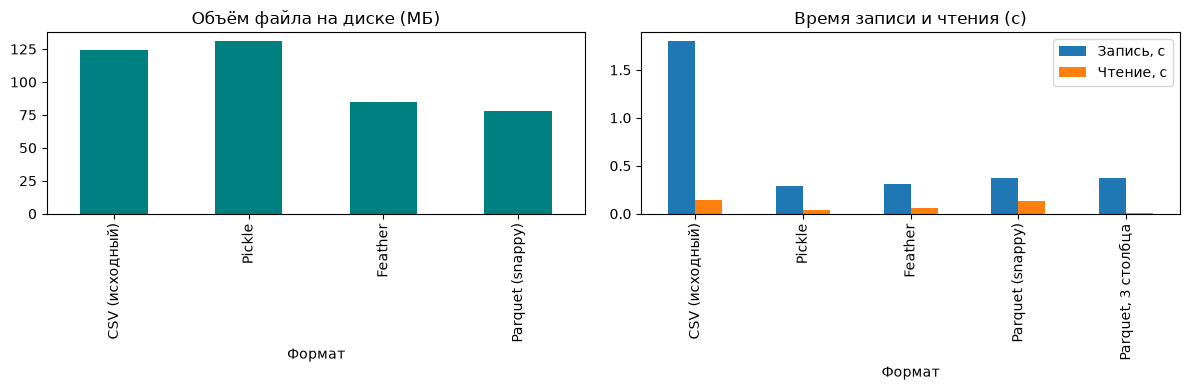

In [3]:
import statistics
import time

import matplotlib.pyplot as plt

from src.config import INTERIM_DIR

# Пути для сохранения разных форматов в data/interim/
paths = {
    "CSV (исходный)": INTERIM_DIR / "source.csv",
    "Pickle": INTERIM_DIR / "source.pkl",
    "Feather": INTERIM_DIR / "source.feather",
    "Parquet (snappy)": INTERIM_DIR / "source.parquet",
}

results_step9 = []

for name, path in paths.items():
    # 1. Замер времени записи (3 повтора, берём медиану)
    write_times = []
    for _ in range(3):
        t0 = time.perf_counter()
        if "CSV" in name:
            df_reviews.to_csv(path, index=False)
        elif "Pickle" in name:
            df_reviews.to_pickle(path)
        elif "Feather" in name:
            df_reviews.to_feather(path)
        elif "Parquet" in name:
            df_reviews.to_parquet(path, compression="snappy", index=False)
        write_times.append(time.perf_counter() - t0)

    # 2. Замер времени чтения (первый холостой прогрев кэша + 3 повтора)
    if "CSV" in name:
        pd.read_csv(path)
    elif "Pickle" in name:
        pd.read_pickle(path)
    elif "Feather" in name:
        pd.read_feather(path)
    elif "Parquet" in name:
        pd.read_parquet(path)

    read_times = []
    for _ in range(3):
        t0 = time.perf_counter()
        if "CSV" in name:
            pd.read_csv(path)
        elif "Pickle" in name:
            pd.read_pickle(path)
        elif "Feather" in name:
            pd.read_feather(path)
        elif "Parquet" in name:
            pd.read_parquet(path)
        read_times.append(time.perf_counter() - t0)

    size_mb = path.stat().st_size / (1024 ** 2)
    results_step9.append({
        "Формат": name,
        "Объём, МБ": round(size_mb, 2),
        "Запись, с": round(statistics.median(write_times), 3),
        "Чтение, с": round(statistics.median(read_times), 3),
    })

# Дополнительно: чтение только 3 столбцов из Parquet
pq_path = paths["Parquet (snappy)"]
read_3cols = []
for _ in range(3):
    t0 = time.perf_counter()
    pd.read_parquet(pq_path, columns=["review_id", "stars", "date"])
    read_3cols.append(time.perf_counter() - t0)

results_step9.append({
    "Формат": "Parquet, 3 столбца",
    "Объём, МБ": results_step9[-1]["Объём, МБ"],
    "Запись, с": results_step9[-1]["Запись, с"],
    "Чтение, с": round(statistics.median(read_3cols), 3),
})

# Формируем Таблицу 6 для отчёта
df_table6 = pd.DataFrame(results_step9)
csv_size = df_table6.loc[0, "Объём, МБ"]
df_table6["Отношение объёма к CSV"] = (df_table6["Объём, МБ"] / csv_size).round(2)

print("Таблица 6 — Результаты измерения сериализации:")
display(df_table6)

# Строим столбчатую диаграмму для отчёта
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_table6.iloc[:-1].plot(x="Формат", y="Объём, МБ", kind="bar", ax=axes[0], color="teal", legend=False, title="Объём файла на диске (МБ)")
df_table6.plot(x="Формат", y=["Запись, с", "Чтение, с"], kind="bar", ax=axes[1], title="Время записи и чтения (с)")
plt.tight_layout()
plt.show()

In [4]:
# Объединяем отзывы с городами и штатами из таблицы заведений для проверки категориальных типов
df_raw_schema = df_reviews.merge(
    df_business[["business_id", "city", "state", "is_open"]],
    on="business_id",
    how="left"
)
raw_pq_path = INTERIM_DIR / "source_untyped.parquet"
typed_pq_path = INTERIM_DIR / "source_typed.parquet"
df_raw_schema.to_parquet(raw_pq_path, compression="zstd", index=False)

# 1. Замеры ДО оптимизации типов
mem_before = df_raw_schema.memory_usage(deep=True).sum() / (1024 ** 2)
size_before = raw_pq_path.stat().st_size / (1024 ** 2)

t0 = time.perf_counter()
pd.read_parquet(raw_pq_path)
read_before = time.perf_counter() - t0

t0 = time.perf_counter()
df_raw_schema.groupby("state")["stars"].mean()
group_before = time.perf_counter() - t0

# Доля уникальных значений текстовых столбцов (критерий перевода в category < 50%)
print("Доля уникальных значений строковых столбцов:")
for col in ["review_id", "user_id", "business_id", "city", "state", "text"]:
    ratio = df_raw_schema[col].nunique() / len(df_raw_schema)
    print(f"  {col:<12}: {ratio:.4%}")

# 2. Применяем оптимальную схему типов
schema_types = {
    "review_id": "string",
    "user_id": "string",
    "business_id": "string",
    "stars": "int8",          # Оценка от 1 до 5 (1 байт вместо 8)
    "useful": "int16",        # Голоса до 32 767 (2 байта вместо 8)
    "funny": "int16",
    "cool": "int16",
    "text": "string",         # Свободный текст — тип Arrow string (НЕ category!)
    "city": "category",       # Ограниченный набор городов — тип category
    "state": "category",      # Штаты — тип category
    "is_open": "boolean",     # Логический флаг (1 байт)
}

df_typed = df_raw_schema.astype(schema_types)
df_typed["date"] = pd.to_datetime(df_typed["date"])
df_typed.to_parquet(typed_pq_path, compression="zstd", index=False)

# 3. Замеры ПОСЛЕ оптимизации типов
mem_after = df_typed.memory_usage(deep=True).sum() / (1024 ** 2)
size_after = typed_pq_path.stat().st_size / (1024 ** 2)

t0 = time.perf_counter()
pd.read_parquet(typed_pq_path)
read_after = time.perf_counter() - t0

t0 = time.perf_counter()
df_typed.groupby("state", observed=True)["stars"].mean()
group_after = time.perf_counter() - t0

# Формируем Таблицу 7 для отчёта
df_table7 = pd.DataFrame([
    {"Показатель": "Объём файла на диске, МБ", "До оптимизации": round(size_before, 2), "После": round(size_after, 2), "Изменение": f"-{(1 - size_after/size_before)*100:.1f}%"},
    {"Показатель": "Объём в памяти, МБ", "До оптимизации": round(mem_before, 2), "После": round(mem_after, 2), "Изменение": f"-{(1 - mem_after/mem_before)*100:.1f}%"},
    {"Показатель": "Время чтения, с", "До оптимизации": round(read_before, 3), "После": round(read_after, 3), "Изменение": f"в {read_before/read_after:.2f} раза быстрее"},
    {"Показатель": "Время группировки, с", "До оптимизации": round(group_before, 4), "После": round(group_after, 4), "Изменение": f"в {group_before/group_after:.2f} раза быстрее"},
    {"Показатель": "Число столбцов типа category", "До оптимизации": 0, "После": 2, "Изменение": "+2 (city, state)"},
])

print("\nТаблица 7 — Результаты оптимизации схемы данных:")
display(df_table7)

Доля уникальных значений строковых столбцов:
  review_id   : 100.0000%
  user_id     : 71.8430%
  business_id : 5.7255%
  city        : 0.2855%
  state       : 0.0085%
  text        : 99.9080%

Таблица 7 — Результаты оптимизации схемы данных:


,Показатель,До оптимизации,После,Изменение
0,"Объём файла на диске, МБ",55.3700,55.4100,--0.1%
1,"Объём в памяти, МБ",138.0100,127.3400,-7.7%
2,"Время чтения, с",0.1620,0.1570,в 1.03 раза быстрее
3,"Время группировки, с",0.2618,0.0853,в 3.07 раза быстрее
4,Число столбцов типа category,0.0000,2.0000,"+2 (city, state)"


Версии библиотек: pandas 3.1.0, polars 2.1.0
Таблица 8 — Сравнение производительности pandas и polars:


,Операция,"pandas, с","polars, с",Ускорение (раз)
0,Чтение Parquet,0.1834,0.1529,1.20
1,Фильтрация,0.0270,0.0021,12.56
2,Группировка и агрегирование,0.0119,0.0030,3.97
3,Сортировка,0.0621,0.0077,8.02
4,Соединение таблиц (JOIN),0.0482,0.0057,8.44
5,Цепочка операций (ленивый режим),0.1725,0.0038,45.07


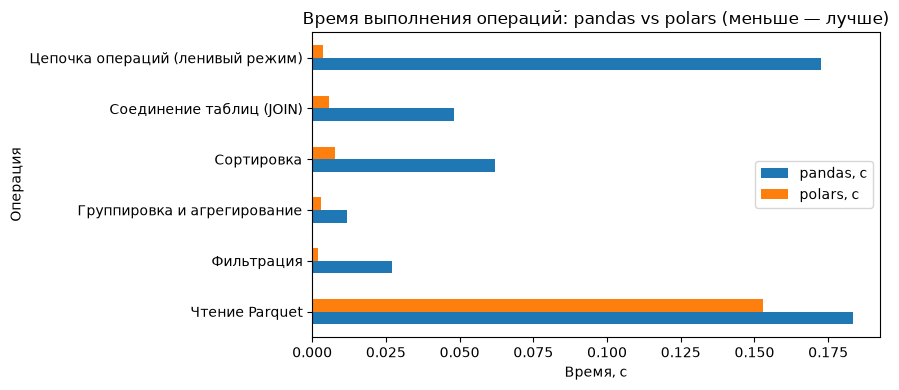

In [5]:
import polars as pl

# Подготовим небольшой справочник заведений в Parquet для теста операции JOIN
biz_lookup_path = INTERIM_DIR / "business_lookup.parquet"
df_business[["business_id", "name", "review_count"]].to_parquet(biz_lookup_path, index=False)

def bench(func, repeats=3):
    times = []
    res = None
    for _ in range(repeats):
        t0 = time.perf_counter()
        res = func()
        times.append(time.perf_counter() - t0)
    return statistics.median(times), res

# 1. Чтение Parquet
t_pd_read, pd_df = bench(lambda: pd.read_parquet(raw_pq_path))
t_pl_read, pl_df = bench(lambda: pl.read_parquet(raw_pq_path))

pd_biz = pd.read_parquet(biz_lookup_path)
pl_biz = pl.read_parquet(biz_lookup_path)

# 2. Фильтрация (useful > 0 и stars >= 4)
t_pd_filt, _ = bench(lambda: pd_df[(pd_df["useful"] > 0) & (pd_df["stars"] >= 4)])
t_pl_filt, _ = bench(lambda: pl_df.filter((pl.col("useful") > 0) & (pl.col("stars") >= 4)))

# 3. Группировка и агрегирование (медиана useful по city)
t_pd_grp, _ = bench(lambda: pd_df.groupby("city")["useful"].median())
t_pl_grp, _ = bench(lambda: pl_df.group_by("city").agg(pl.col("useful").median()))

# 4. Сортировка по убыванию голосов useful
t_pd_sort, _ = bench(lambda: pd_df.sort_values(by="useful", ascending=False))
t_pl_sort, _ = bench(lambda: pl_df.sort("useful", descending=True))

# 5. Соединение таблиц (JOIN со справочником заведений)
t_pd_join, _ = bench(lambda: pd_df.merge(pd_biz, on="business_id", how="left"))
t_pl_join, _ = bench(lambda: pl_df.join(pl_biz, on="business_id", how="left"))

# 6. Цепочка операций целиком (pandas vs ленивый режим polars scan_parquet)
def pd_chain():
    d = pd.read_parquet(raw_pq_path)
    return (
        d[d["useful"] > 0]
        .groupby("city")["stars"]
        .median()
        .sort_values(ascending=False)
    )

def pl_lazy_chain():
    return (
        pl.scan_parquet(raw_pq_path)
        .filter(pl.col("useful") > 0)
        .group_by("city")
        .agg(pl.col("stars").median())
        .sort("stars", descending=True)
        .collect()
    )

t_pd_chain, _ = bench(pd_chain)
t_pl_chain, _ = bench(pl_lazy_chain)

# Формируем Таблицу 8 для отчёта
rows_step11 = [
    ("Чтение Parquet", t_pd_read, t_pl_read),
    ("Фильтрация", t_pd_filt, t_pl_filt),
    ("Группировка и агрегирование", t_pd_grp, t_pl_grp),
    ("Сортировка", t_pd_sort, t_pl_sort),
    ("Соединение таблиц (JOIN)", t_pd_join, t_pl_join),
    ("Цепочка операций (ленивый режим)", t_pd_chain, t_pl_chain),
]

df_table8 = pd.DataFrame([
    {
        "Операция": op,
        "pandas, с": round(t_pd, 4),
        "polars, с": round(t_pl, 4),
        "Ускорение (раз)": round(t_pd / t_pl, 2)
    }
    for op, t_pd, t_pl in rows_step11
])

print(f"Версии библиотек: pandas {pd.__version__}, polars {pl.__version__}")
print("Таблица 8 — Сравнение производительности pandas и polars:")
display(df_table8)

# Диаграмма сравнения
df_table8.plot(x="Операция", y=["pandas, с", "polars, с"], kind="barh", figsize=(9, 4), title="Время выполнения операций: pandas vs polars (меньше — лучше)")
plt.xlabel("Время, с")
plt.tight_layout()
plt.show()